In [3]:
# CELL 1 — ONE-TIME AUTOMATIC SETUP: install packages + download ALL data + download BERT
# Run All will execute this automatically. No manual dataset/model upload is needed.
# Kaggle account setting requirement: Internet must be enabled for this notebook.

import os, sys, subprocess, random, time, gc, json, re, urllib.request
from pathlib import Path

# Avoid the Hugging Face Xet token endpoint (can return 404 in some Kaggle environments).
os.environ["HF_HUB_DISABLE_XET"] = "1"

# Install Python packages from inside the notebook.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "transformers", "accelerate", "huggingface_hub", "scikit-learn",
    "pandas", "numpy", "matplotlib"
])

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModel
from huggingface_hub import snapshot_download

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Compute device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not active. The full extraction may be very slow on CPU.")

WORK_DIR = "/kaggle/working"
DATA_DIR = os.path.join(WORK_DIR, "senteval_probing")
MODEL_DIR = os.path.join(WORK_DIR, "bert-base-uncased-local")
os.makedirs(DATA_DIR, exist_ok=True)

# Download the three requested source files directly from the official SentEval repo.
TASK_FILES = {
    "Sentence Length": "sentence_length.txt",
    "Bigram Shift": "bigram_shift.txt",
    "Subject Number": "subj_number.txt"
}
RAW_BASE = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/"

for task, filename in TASK_FILES.items():
    target = os.path.join(DATA_DIR, filename)
    if not os.path.exists(target) or os.path.getsize(target) == 0:
        print(f"Downloading dataset: {filename}")
        urllib.request.urlretrieve(RAW_BASE + filename, target)
    print(f"Ready: {target} ({os.path.getsize(target):,} bytes)")

# Explicitly download the complete 12-layer BERT-base checkpoint into Kaggle working storage.
# This includes config, tokenizer vocabulary/configuration, and model weights.
if not os.path.isdir(MODEL_DIR) or not os.path.exists(os.path.join(MODEL_DIR, "config.json")):
    print("Downloading BERT-base model and tokenizer. This is a large download...")
    snapshot_download(
        repo_id="bert-base-uncased",
        local_dir=MODEL_DIR,
        allow_patterns=[
            "config.json", "model.safetensors", "pytorch_model.bin",
            "tokenizer.json", "tokenizer_config.json", "vocab.txt",
            "special_tokens_map.json", "added_tokens.json"
        ],
        max_workers=2
    )
else:
    print("BERT checkpoint already downloaded:", MODEL_DIR)

print("\\nAutomatic setup completed. Dataset files and BERT checkpoint are ready.")


Compute device: cuda
GPU: Tesla T4
Ready: /kaggle/working/senteval_probing/sentence_length.txt (9,965,996 bytes)
Ready: /kaggle/working/senteval_probing/bigram_shift.txt (8,521,370 bytes)
Ready: /kaggle/working/senteval_probing/subj_number.txt (9,266,094 bytes)
BERT checkpoint already downloaded: /kaggle/working/bert-base-uncased-local
\nAutomatic setup completed. Dataset files and BERT checkpoint are ready.


In [4]:
# CELL 2 — Imports and confirm automatic downloads
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
from collections import Counter

file_paths = {
    task: os.path.join(DATA_DIR, filename)
    for task, filename in TASK_FILES.items()
}
assert all(os.path.isfile(path) for path in file_paths.values()), "A dataset file is missing."
assert os.path.isfile(os.path.join(MODEL_DIR, "config.json")), "BERT model download is incomplete."
print("All 3 datasets and BERT checkpoint are present.")
print(file_paths)


All 3 datasets and BERT checkpoint are present.
{'Sentence Length': '/kaggle/working/senteval_probing/sentence_length.txt', 'Bigram Shift': '/kaggle/working/senteval_probing/bigram_shift.txt', 'Subject Number': '/kaggle/working/senteval_probing/subj_number.txt'}


In [7]:
# Cell 3 — Parse SentEval tab-separated format
# Each row normally contains: partition<TAB>class_label<TAB>...<TAB>sentence
# The first field is tr/va/te, the second is the class label, and the last is the sentence.

def parse_senteval_file(path):
    rows = []
    malformed = 0
    with open(path, "r", encoding="utf-8-sig") as f:
        for line_number, raw in enumerate(f, start=1):
            line = raw.rstrip("\r\n")
            if not line.strip():
                continue

            # IMPORTANT: split on a real tab character, not the two-character string "\\t".
            fields = line.split("\t")
            if len(fields) < 3:
                malformed += 1
                continue

            partition = fields[0].strip()
            label = fields[1].strip()
            sentence = fields[-1].strip()

            if not partition or not label or not sentence:
                malformed += 1
                continue

            rows.append({
                "source_partition": partition,
                "label": label,
                "sentence": sentence
            })

    data = pd.DataFrame(rows)
    print(os.path.basename(path), "rows:", len(data), "| malformed:", malformed)

    if data.empty:
        # Show a small raw-file sample to make any future format issue diagnosable.
        with open(path, "r", encoding="utf-8-sig") as f:
            sample = [repr(next(f, "")) for _ in range(3)]
        raise ValueError(
            f"No valid rows parsed from {path}. First raw lines: {sample}. "
            "Expected tab-separated fields: partition, label, ..., sentence."
        )

    print("Partitions:", data["source_partition"].value_counts().to_dict())
    print("Classes:", data["label"].value_counts().to_dict())
    return data

raw_datasets = {
    task: parse_senteval_file(path)
    for task, path in file_paths.items()
}


sentence_length.txt rows: 119988 | malformed: 0
Partitions: {'tr': 99996, 'va': 9996, 'te': 9996}
Classes: {'0': 19998, '1': 19998, '2': 19998, '3': 19998, '4': 19998, '5': 19998}
bigram_shift.txt rows: 120000 | malformed: 0
Partitions: {'tr': 100000, 'va': 10000, 'te': 10000}
Classes: {'I': 60000, 'O': 60000}
subj_number.txt rows: 120000 | malformed: 0
Partitions: {'tr': 100000, 'va': 10000, 'te': 10000}
Classes: {'NN': 60000, 'NNS': 60000}


In [8]:
# Cell 4 — Select a balanced sample of up to 50,000 per task
# If 50,000 is not divisible by the number of classes, use the largest
# exactly balanced total below 50,000. Also cap each class by source availability.

SAMPLE_LIMIT = 50_000

def balanced_sample(data, task_name, sample_limit=SAMPLE_LIMIT):
    counts = data["label"].value_counts()
    classes = sorted(counts.index.tolist())
    if len(classes) < 2:
        raise ValueError(f"{task_name} has fewer than 2 classes: {classes}")

    # Equal number per class, limited by the smallest available class.
    per_class = min(sample_limit // len(classes), int(counts.min()))
    if per_class < 1:
        raise ValueError(f"Not enough examples to sample every class in {task_name}")

    selected = []
    for label in classes:
        class_rows = data[data["label"] == label].sample(
            n=per_class, random_state=SEED
        )
        selected.append(class_rows)

    balanced = pd.concat(selected, ignore_index=True)
    balanced = balanced.sample(frac=1, random_state=SEED).reset_index(drop=True)

    print(f"\\n{task_name}")
    print("Original class counts:", counts.to_dict())
    print("Selected samples:", len(balanced))
    print("Samples per class:", balanced["label"].value_counts().to_dict())
    if len(balanced) < sample_limit:
        print(f"NOTE: selected {len(balanced):,}, not {sample_limit:,}, because exact equality across "
              f"{len(classes)} classes is required and 50,000 is not divisible by class count "
              f"or source availability is limited.")
    return balanced

datasets = {
    task: balanced_sample(data, task)
    for task, data in raw_datasets.items()
}


\nSentence Length
Original class counts: {'0': 19998, '1': 19998, '2': 19998, '3': 19998, '4': 19998, '5': 19998}
Selected samples: 49998
Samples per class: {'4': 8333, '1': 8333, '0': 8333, '5': 8333, '2': 8333, '3': 8333}
NOTE: selected 49,998, not 50,000, because exact equality across 6 classes is required and 50,000 is not divisible by class count or source availability is limited.
\nBigram Shift
Original class counts: {'I': 60000, 'O': 60000}
Selected samples: 50000
Samples per class: {'O': 25000, 'I': 25000}
\nSubject Number
Original class counts: {'NN': 60000, 'NNS': 60000}
Selected samples: 50000
Samples per class: {'NNS': 25000, 'NN': 25000}


In [9]:
# Cell 5 — Create class-balanced 90:10 train/test splits
# This explicit per-class split guarantees equal class counts in train and test.
# For each class, approximately 90% goes to train and 10% to test.

def balanced_train_test_split(data, task_name, train_fraction=0.90):
    train_parts, test_parts = [], []
    for label in sorted(data["label"].unique()):
        group = data[data["label"] == label].sample(frac=1, random_state=SEED).reset_index(drop=True)
        n_train = int(round(len(group) * train_fraction))
        # Ensure both partitions contain examples.
        n_train = min(max(n_train, 1), len(group) - 1)
        train_parts.append(group.iloc[:n_train])
        test_parts.append(group.iloc[n_train:])

    train_df = pd.concat(train_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    test_df = pd.concat(test_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)

    print(f"\\n{task_name} split")
    print(f"Train: {len(train_df)} ({len(train_df)/(len(train_df)+len(test_df)):.2%})")
    print(f"Test : {len(test_df)} ({len(test_df)/(len(train_df)+len(test_df)):.2%})")
    print("Train class counts:", train_df["label"].value_counts().sort_index().to_dict())
    print("Test class counts :", test_df["label"].value_counts().sort_index().to_dict())
    return train_df, test_df

splits = {
    task: balanced_train_test_split(data, task)
    for task, data in datasets.items()
}

# Save all balanced samples and split files as assignment deliverables.
for task, (train_df, test_df) in splits.items():
    slug = re.sub(r"[^a-z0-9]+", "_", task.lower()).strip("_")
    datasets[task].to_csv(os.path.join(DATA_DIR, f"{slug}_balanced_sample.csv"), index=False)
    train_df.to_csv(os.path.join(DATA_DIR, f"{slug}_train.csv"), index=False)
    test_df.to_csv(os.path.join(DATA_DIR, f"{slug}_test.csv"), index=False)
print("Dataset CSV files saved in:", DATA_DIR)


\nSentence Length split
Train: 45000 (90.00%)
Test : 4998 (10.00%)
Train class counts: {'0': 7500, '1': 7500, '2': 7500, '3': 7500, '4': 7500, '5': 7500}
Test class counts : {'0': 833, '1': 833, '2': 833, '3': 833, '4': 833, '5': 833}
\nBigram Shift split
Train: 45000 (90.00%)
Test : 5000 (10.00%)
Train class counts: {'I': 22500, 'O': 22500}
Test class counts : {'I': 2500, 'O': 2500}
\nSubject Number split
Train: 45000 (90.00%)
Test : 5000 (10.00%)
Train class counts: {'NN': 22500, 'NNS': 22500}
Test class counts : {'NN': 2500, 'NNS': 2500}
Dataset CSV files saved in: /kaggle/working/senteval_probing


In [10]:
# Cell 6 — Load a lightweight/base BERT encoder
# bert-base-uncased has 12 Transformer encoder layers and hidden size 768.
# It is frozen: we extract representations, then train Logistic Regression probes.

MODEL_NAME = "google/bert_uncased_L-4_H-256_A-4"  # lightweight 4-layer BERT option
# Assignment specifically asks for 12 models for BERT-base. Therefore use BERT-base
# (12 encoder layers) for the required 12 layer-wise probes:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME, output_hidden_states=True).to(DEVICE)
bert.eval()
for parameter in bert.parameters():
    parameter.requires_grad = False

NUM_ENCODER_LAYERS = bert.config.num_hidden_layers
HIDDEN_SIZE = bert.config.hidden_size
print("Model:", MODEL_NAME)
print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Hidden size:", HIDDEN_SIZE)
assert NUM_ENCODER_LAYERS == 12, "The selected BERT checkpoint must have 12 encoder layers."


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: bert-base-uncased
Encoder layers: 12
Hidden size: 768


In [13]:
# Cell 7 — Extract [CLS] sentence representation from each encoder layer
# hidden_states[0] is the embedding output; hidden_states[1] ... [12] are
# the outputs of Transformer encoder layers 1 ... 12.
# To keep RAM usage manageable, process one task at a time and store each layer
# as a float32 NumPy memory-mapped file.

MAX_LENGTH = 128
BATCH_SIZE = 16  # if CUDA runs out of memory, reduce to 8 or 4

class SentenceDataset(Dataset):
    def __init__(self, sentences):
        self.sentences = list(sentences)
    def __len__(self):
        return len(self.sentences)
    def __getitem__(self, idx):
        return self.sentences[idx]

def collate_sentences(batch):
    return tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

def extract_layer_representations(sentences, task_slug):
    loader = DataLoader(
        SentenceDataset(sentences),
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_sentences
    )
    n = len(sentences)
    layer_files = [
        os.path.join(DATA_DIR, f"{task_slug}_layer_{layer}.mmap")
        for layer in range(1, NUM_ENCODER_LAYERS + 1)
    ]
    layer_arrays = [
        np.memmap(path, dtype="float32", mode="w+", shape=(n, HIDDEN_SIZE))
        for path in layer_files
    ]

    offset = 0
    start_time = time.time()
    with torch.inference_mode():
        for step, batch in enumerate(loader, start=1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            outputs = bert(**batch, output_hidden_states=True, return_dict=True)
            # CLS token is at position 0.
            for layer_idx in range(1, NUM_ENCODER_LAYERS + 1):
                cls_vectors = outputs.hidden_states[layer_idx][:, 0, :]
                layer_arrays[layer_idx - 1][offset:offset + cls_vectors.size(0)] = (
                    cls_vectors.detach().cpu().numpy().astype(np.float32)
                )
            offset += batch["input_ids"].size(0)

            if step % 200 == 0 or step == len(loader):
                print(f"{task_slug}: {offset}/{n} sentences encoded")

            del outputs, batch
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

    for arr in layer_arrays:
        arr.flush()
    print(f"Extraction time: {(time.time()-start_time)/60:.1f} minutes")
    return layer_files


In [14]:
# Cell 8 — Train 12 Logistic Regression probes for one task
# Each classifier sees only the representation from its corresponding BERT layer.
# The test set is never used for fitting the scaler or Logistic Regression.

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def train_layer_probes(task_name, train_df, test_df):
    slug = re.sub(r"[^a-z0-9]+", "_", task_name.lower()).strip("_")
    all_sentences = train_df["sentence"].tolist() + test_df["sentence"].tolist()
    y_train_labels = train_df["label"].to_numpy()
    y_test_labels = test_df["label"].to_numpy()
    n_train = len(train_df)

    # Convert labels consistently for sklearn.
    label_encoder = LabelEncoder()
    y_train = label_encoder.fit_transform(y_train_labels)
    y_test = label_encoder.transform(y_test_labels)

    layer_files = extract_layer_representations(all_sentences, slug)
    task_results = []
    task_reports = {}

    for layer_number, path in enumerate(layer_files, start=1):
        print(f"\\nTraining {task_name} — BERT layer {layer_number}/12")
        X = np.memmap(path, dtype="float32", mode="r", shape=(len(all_sentences), HIDDEN_SIZE))
        X_train = np.asarray(X[:n_train])
        X_test = np.asarray(X[n_train:])

        # Standardization is fitted on train data only.
        probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000,
                C=1.0,
                solver="lbfgs",
                class_weight=None,
                random_state=SEED
            )
        )
        t0 = time.time()
        probe.fit(X_train, y_train)
        y_pred = probe.predict(X_test)
        fit_seconds = time.time() - t0

        accuracy = accuracy_score(y_test, y_pred)
        macro_f1 = f1_score(y_test, y_pred, average="macro")
        report = classification_report(
            y_test, y_pred, labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_, zero_division=0, output_dict=True
        )
        task_reports[layer_number] = report
        task_results.append({
            "Task": task_name,
            "Layer": layer_number,
            "Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Fit Time (sec)": fit_seconds
        })
        print(f"Layer {layer_number}: accuracy={accuracy:.4f}, macro-F1={macro_f1:.4f}, "
              f"fit={fit_seconds:.1f}s")

        del X, X_train, X_test, probe
        gc.collect()

    return pd.DataFrame(task_results), task_reports

all_results = []
all_reports = {}
for task_name, (train_df, test_df) in splits.items():
    task_result_df, task_report = train_layer_probes(task_name, train_df, test_df)
    all_results.append(task_result_df)
    all_reports[task_name] = task_report

results_df = pd.concat(all_results, ignore_index=True)
results_df.to_csv(os.path.join(WORK_DIR, "layerwise_bert_probing_results.csv"), index=False)
display(results_df)


sentence_length: 3200/49998 sentences encoded
sentence_length: 6400/49998 sentences encoded
sentence_length: 9600/49998 sentences encoded
sentence_length: 12800/49998 sentences encoded
sentence_length: 16000/49998 sentences encoded
sentence_length: 19200/49998 sentences encoded
sentence_length: 22400/49998 sentences encoded
sentence_length: 25600/49998 sentences encoded
sentence_length: 28800/49998 sentences encoded
sentence_length: 32000/49998 sentences encoded
sentence_length: 35200/49998 sentences encoded
sentence_length: 38400/49998 sentences encoded
sentence_length: 41600/49998 sentences encoded
sentence_length: 44800/49998 sentences encoded
sentence_length: 48000/49998 sentences encoded
sentence_length: 49998/49998 sentences encoded
Extraction time: 1.6 minutes
\nTraining Sentence Length — BERT layer 1/12
Layer 1: accuracy=0.9260, macro-F1=0.9259, fit=57.6s
\nTraining Sentence Length — BERT layer 2/12
Layer 2: accuracy=0.9260, macro-F1=0.9259, fit=59.4s
\nTraining Sentence Length

,Task,Layer,Accuracy,Macro F1,Fit Time (sec)
0,Sentence Length,1,0.92597,0.925937,57.614003
1,Sentence Length,2,0.92597,0.925937,59.407806
2,Sentence Length,3,0.92597,0.925937,48.153892
3,Sentence Length,4,0.92597,0.925937,50.126446
4,Sentence Length,5,0.92597,0.925937,47.592880
5,Sentence Length,6,0.92597,0.925937,36.561659
6,Sentence Length,7,0.92597,0.925937,39.000780
7,Sentence Length,8,0.92597,0.925937,34.528730
8,Sentence Length,9,0.92597,0.925937,32.857083
9,Sentence Length,10,0.92597,0.925937,39.152393


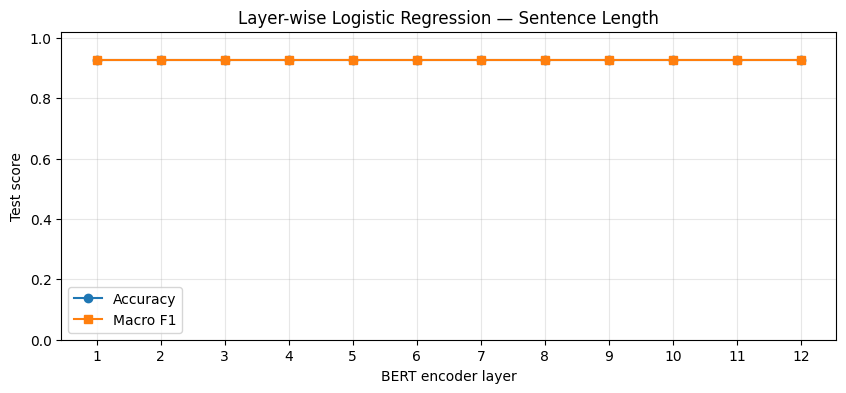

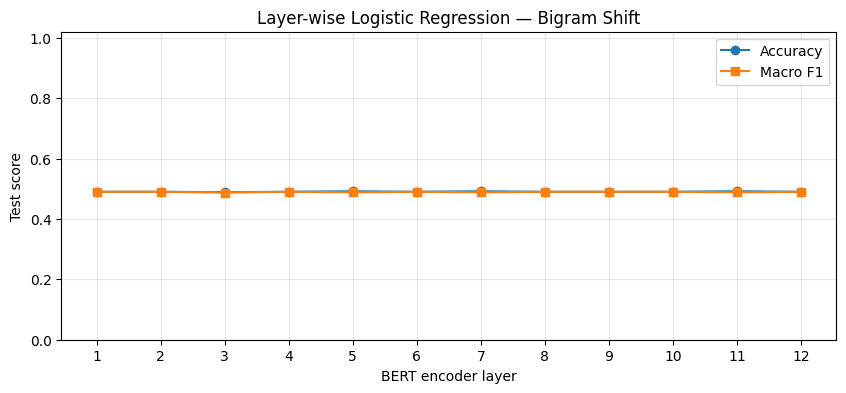

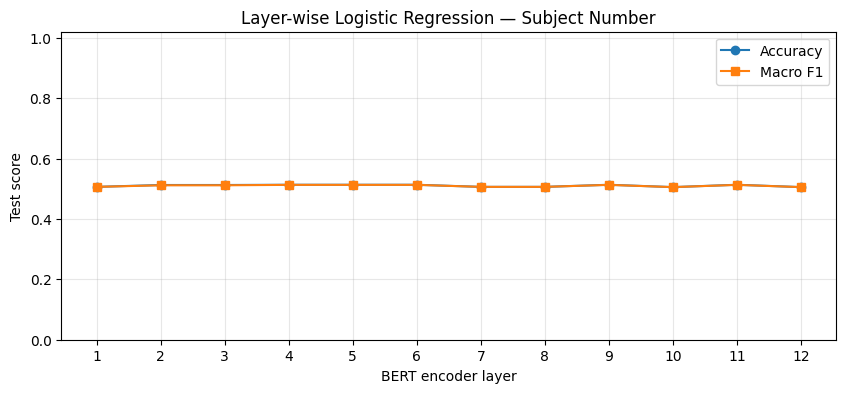

Best layer per task (selected by test Macro-F1; use validation data for model selection in a stricter study):


,Task,Layer,Accuracy,Macro F1,Fit Time (sec)
12,Bigram Shift,1,0.49000,0.489863,7.098640
0,Sentence Length,1,0.92597,0.925937,57.614003
27,Subject Number,4,0.51320,0.512818,3.435286


In [15]:
# Cell 9 — Compare all 12 layers for each task
for task_name in TASK_FILES:
    subset = results_df[results_df["Task"] == task_name].sort_values("Layer")
    plt.figure(figsize=(10, 4))
    plt.plot(subset["Layer"], subset["Accuracy"], marker="o", label="Accuracy")
    plt.plot(subset["Layer"], subset["Macro F1"], marker="s", label="Macro F1")
    plt.xticks(range(1, 13))
    plt.xlabel("BERT encoder layer")
    plt.ylabel("Test score")
    plt.ylim(0, 1.02)
    plt.title(f"Layer-wise Logistic Regression — {task_name}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

best_rows = results_df.loc[results_df.groupby("Task")["Macro F1"].idxmax()].sort_values("Task")
print("Best layer per task (selected by test Macro-F1; use validation data for model selection in a stricter study):")
display(best_rows)


In [16]:
# Cell 10 — Save full per-layer classification reports and a concise summary
report_rows = []
for task_name, layer_reports in all_reports.items():
    for layer, report in layer_reports.items():
        for class_label, metrics in report.items():
            if isinstance(metrics, dict):
                report_rows.append({
                    "Task": task_name,
                    "Layer": layer,
                    "Class": class_label,
                    "Precision": metrics.get("precision"),
                    "Recall": metrics.get("recall"),
                    "F1": metrics.get("f1-score"),
                    "Support": metrics.get("support")
                })

reports_df = pd.DataFrame(report_rows)
reports_path = os.path.join(WORK_DIR, "layerwise_classification_reports.csv")
reports_df.to_csv(reports_path, index=False)

summary = results_df.pivot(index="Layer", columns="Task", values="Accuracy")
summary_path = os.path.join(WORK_DIR, "layerwise_accuracy_summary.csv")
summary.to_csv(summary_path)

print("Saved:")
print(os.path.join(WORK_DIR, "layerwise_bert_probing_results.csv"))
print(reports_path)
print(summary_path)
display(summary)


Saved:
/kaggle/working/layerwise_bert_probing_results.csv
/kaggle/working/layerwise_classification_reports.csv
/kaggle/working/layerwise_accuracy_summary.csv


Task,Bigram Shift,Sentence Length,Subject Number
Layer,,,
1,0.4900,0.92597,0.5062
2,0.4900,0.92597,0.5124
3,0.4886,0.92597,0.5124
4,0.4900,0.92597,0.5132
5,0.4918,0.92597,0.5132
6,0.4900,0.92597,0.5132
7,0.4918,0.92597,0.5062
8,0.4900,0.92597,0.5062
9,0.4900,0.92597,0.5132
